# Olist E-Commerce: Delivery Performance & Customer Satisfaction
## Notebook 01: Data Loading, Quality Checks and Cleaning

**Business problem.** Late deliveries likely hurt customer satisfaction on a marketplace where sellers ship and carriers deliver. This project finds where delivery failures are concentrated, how strongly they relate to review scores, and where operations should act first.

**Questions**
1. How do orders, revenue and average order value change over time? Is there seasonality?
2. What share of orders arrive late, and how does it vary by state, category and seller?
3. How strongly are delivery delay and review score related? Is there a delay threshold where scores drop sharply?
4. Which categories and sellers combine high revenue with poor delivery or satisfaction?
5. How do freight cost and delivery-estimate accuracy relate to satisfaction?

**Data:** [Olist Brazilian E-Commerce (Kaggle)](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce). It is downloaded automatically with `kagglehub`.
**Tables used:** orders, order items, reviews, customers, products, sellers, category translation. (Payments and geolocation are not needed for these questions.)

## 1. Installing and loading the data

In [14]:
%pip install kagglehub

In [15]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

import kagglehub

# Downloads the dataset and returns the folder path
DATA_DIR = Path(kagglehub.dataset_download("olistbr/brazilian-ecommerce"))
print("Data folder:", DATA_DIR)
print("Files found:", sorted(p.name for p in DATA_DIR.glob("*.csv")))

PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    "orders": "olist_orders_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "translation": "product_category_name_translation.csv",
}

tables = {name: pd.read_csv(DATA_DIR / fname) for name, fname in FILES.items()}
orders, items, reviews = tables["orders"], tables["items"], tables["reviews"]
customers, products, sellers = tables["customers"], tables["products"], tables["sellers"]
translation = tables["translation"]

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
Data folder: /kaggle/input/brazilian-ecommerce
Files found: ['olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_orders_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv']


## 2. First look at every table
For each table: the first rows, the column types, and the missing values.

In [16]:
for name, df in tables.items():
    print(f"\n {name.upper()}")
    print(df.head())
    print(df.info())
    print(df.isnull().sum())


 ORDERS
                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49  2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06  2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39  2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018-07-26 14:31:00         

## 3. Data quality checks
We investigate first and change nothing yet.

### 3.1 Duplicates, keys and broken links between tables
One order can have several items and even several reviews, so we must know what one row means in each table. Joining at the wrong level inflates revenue.

In [17]:
print("Fully duplicated rows per table:")
for name, df in tables.items():
    print(f"  {name}: {df.duplicated().sum()}")

print("\nKey checks")
print("orders: order_id unique?            ", orders["order_id"].is_unique)
print("customers: customer_id unique?      ", customers["customer_id"].is_unique)
print("products: product_id unique?        ", products["product_id"].is_unique)
print("sellers: seller_id unique?          ", sellers["seller_id"].is_unique)
print("items: duplicate (order_id, item_id)", items.duplicated(["order_id", "order_item_id"]).sum())
print("reviews: repeated review_id rows    ", reviews["review_id"].duplicated().sum())
print("reviews: orders with >1 review      ", (reviews.groupby("order_id").size() > 1).sum())

print("\nBroken links (should be 0)")
print("orders without a matching customer: ", (~orders["customer_id"].isin(customers["customer_id"])).sum())
print("items without a matching order:     ", (~items["order_id"].isin(orders["order_id"])).sum())
print("items without a matching product:   ", (~items["product_id"].isin(products["product_id"])).sum())
print("items without a matching seller:    ", (~items["seller_id"].isin(sellers["seller_id"])).sum())
print("reviews without a matching order:   ", (~reviews["order_id"].isin(orders["order_id"])).sum())
print("orders that have no items:          ", (~orders["order_id"].isin(items["order_id"])).sum())

Fully duplicated rows per table:
  orders: 0
  items: 0
  reviews: 0
  customers: 0
  products: 0
  sellers: 0
  translation: 0

Key checks
orders: order_id unique?             True
customers: customer_id unique?       True
products: product_id unique?         True
sellers: seller_id unique?           True
items: duplicate (order_id, item_id) 0
reviews: repeated review_id rows     814
reviews: orders with >1 review       547

Broken links (should be 0)
orders without a matching customer:  0
items without a matching order:      0
items without a matching product:    0
items without a matching seller:     0
reviews without a matching order:    0
orders that have no items:           775


### 3.2 Orders: dates and status
The date columns are text, so we convert a *copy* to check them. Missing delivery dates are only a problem if the order was supposed to be delivered.

In [18]:
DATE_COLS = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

orders_check = orders.copy()
for c in DATE_COLS:
    orders_check[c] = pd.to_datetime(orders_check[c], errors="coerce")

print("Order status counts:")
print(orders_check["order_status"].value_counts())

print("\nMissing dates by order status:")
print(orders_check[DATE_COLS].isna().groupby(orders_check["order_status"]).sum())

o = orders_check
print("\nLogic checks")
print("delivered but no delivery date:      ", ((o.order_status == "delivered") & o.order_delivered_customer_date.isna()).sum())
print("delivery before purchase:            ", (o.order_delivered_customer_date < o.order_purchase_timestamp).sum())
print("delivery before carrier pickup:      ", (o.order_delivered_customer_date < o.order_delivered_carrier_date).sum())
print("estimated date before purchase:      ", (o.order_estimated_delivery_date < o.order_purchase_timestamp).sum())
print("\nPurchase dates run from", o.order_purchase_timestamp.min(), "to", o.order_purchase_timestamp.max())

Order status counts:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Missing dates by order status:
              order_purchase_timestamp  order_approved_at  \
order_status                                                
approved                             0                  0   
canceled                             0                141   
created                              0                  5   
delivered                            0                 14   
invoiced                             0                  0   
processing                           0                  0   
shipped                              0                  0   
unavailable                          0                  0   

              order_delivered_carrier_date  order_delivered_customer_date  \
order_status                                        

#### Data Quality Checks

- No fully duplicated rows were found.
- Primary identifiers were unique, and no broken foreign-key links were found.
- 775 orders had no matching items.
- 8 delivered orders had missing delivery dates.
- 23 orders had delivery dates earlier than carrier pickup.
- 547 orders had multiple reviews.

count    96470.000000
mean        12.093604
std          9.551380
min          0.000000
50%         10.000000
90%         23.000000
99%         46.000000
max        209.000000
Name: delivery_days, dtype: float64


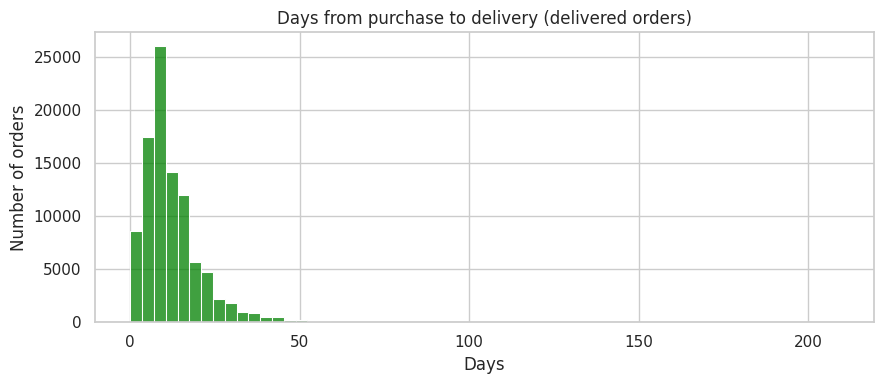

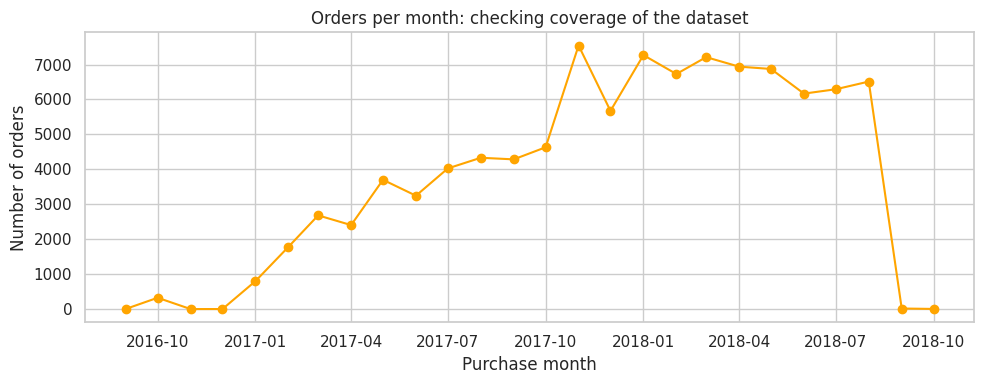

In [26]:
# How long do deliveries take? Outliers
delivered = o[(o.order_status == "delivered") & o.order_delivered_customer_date.notna()].copy()
delivered["delivery_days"] = (
    delivered.order_delivered_customer_date - delivered.order_purchase_timestamp
).dt.days

print(delivered["delivery_days"].describe(percentiles=[0.5, 0.9, 0.99]))

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(delivered["delivery_days"], bins=60, ax=ax, color="green")
ax.set_title("Days from purchase to delivery (delivered orders)")
ax.set_xlabel("Days")
ax.set_ylabel("Number of orders")
plt.tight_layout()
plt.show()

# Orders per month: are the first and last months incomplete?
monthly = o.set_index("order_purchase_timestamp").resample("MS").size()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly.index, monthly.values, marker="o", color="orange")
ax.set_title("Orders per month: checking coverage of the dataset")
ax.set_xlabel("Purchase month")
ax.set_ylabel("Number of orders")
plt.tight_layout()
plt.show()

#### Delivery Time

Average delivery time was 12.1 days, with a median of 10 days. The 90th percentile was 23 days, while the maximum was 209 days. Most orders arrived relatively quickly, but a small number experienced long delays.

Monthly order counts were low at the beginning and end of the dataset, suggesting incomplete coverage.

### 3.3 Order items: price and freight

               price  freight_value
count  112650.000000  112650.000000
mean      120.653739      19.990320
std       183.633928      15.806405
min         0.850000       0.000000
25%        39.900000      13.080000
50%        74.990000      16.260000
75%       134.900000      21.150000
max      6735.000000     409.680000

IQR upper fence for price: 277.40
Items above fence: 8,427 (7.5%)
Items with price <= 0: 0
Items with freight = 0: 383


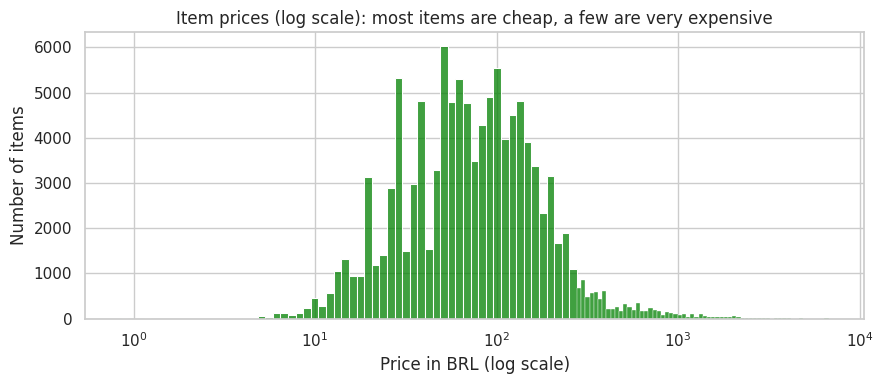

In [29]:
print(items[["price", "freight_value"]].describe())

q1, q3 = items["price"].quantile([0.25, 0.75])
price_fence = q3 + 1.5 * (q3 - q1)

print(f"\nIQR upper fence for price: {price_fence:,.2f}")
print(f"Items above fence: {(items.price > price_fence).sum():,} ({(items.price > price_fence).mean():.1%})")
print("Items with price <= 0:", (items.price <= 0).sum())
print("Items with freight = 0:", (items.freight_value == 0).sum())

fig, ax = plt.subplots(figsize=(9, 4))

prices = items.loc[items.price > 0, "price"]
sns.histplot(prices[prices <= price_fence], bins=60, log_scale=True, ax=ax, color="green")
sns.histplot(prices[prices > price_fence], bins=60, log_scale=True, ax=ax, color="green")

ax.set_title("Item prices (log scale): most items are cheap, a few are very expensive")
ax.set_xlabel("Price in BRL (log scale)")
ax.set_ylabel("Number of items")

plt.tight_layout()
plt.show()



### 3.4 Products and categories

In [21]:
print("Products with missing category:", products["product_category_name"].isna().sum())

untranslated = sorted(set(products["product_category_name"].dropna()) - set(translation["product_category_name"]))
print("Categories with no English translation:", untranslated)

print("Products with zero weight:", (products["product_weight_g"] == 0).sum())

no_cat_ids = products.loc[products["product_category_name"].isna(), "product_id"]
print(f"Share of order items affected by missing category: {items['product_id'].isin(no_cat_ids).mean():.2%}")

Products with missing category: 610
Categories with no English translation: ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']
Products with zero weight: 4
Share of order items affected by missing category: 1.42%


### 3.5 Reviews
Reviews are voluntary, so we only see customers who chose to respond. That is a limitation to state in the final report, not something to fix.

review_score
1    11.5
2     3.2
3     8.2
4    19.3
5    57.8
Name: proportion, dtype: float64

Scores outside 1-5: 0
Reviews with no comment text: 58.7%


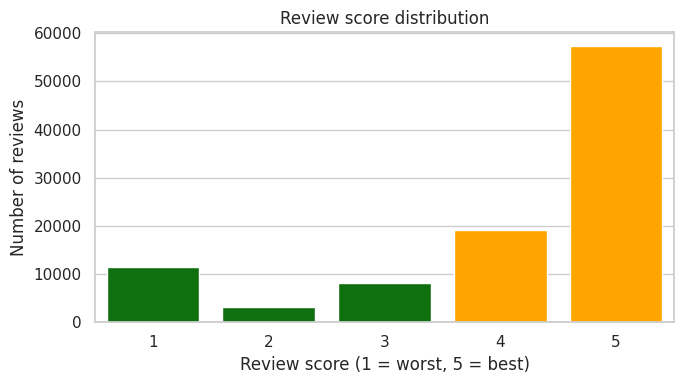

In [28]:
print(reviews["review_score"].value_counts(normalize=True).sort_index().mul(100).round(1))
print("\nScores outside 1-5:", (~reviews["review_score"].between(1, 5)).sum())
print("Reviews with no comment text: {:.1%}".format(reviews["review_comment_message"].isna().mean()))

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(x="review_score", data=reviews, ax=ax, color="green")

for patch in ax.patches:
    if patch.get_x() >= 2:
        patch.set_facecolor("orange")

ax.set_title("Review score distribution")
ax.set_xlabel("Review score (1 = worst, 5 = best)")
ax.set_ylabel("Number of reviews")
plt.tight_layout()
plt.show()

77.1% of reviews received four or five stars, while 11.5% received one star. No scores fell outside the valid 1–5 range. 58.7% of reviews had no written comment.

### 3.6 Audit Notes

1. **Tables and joins:** Items and reviews are not strictly one row per order. Items contain multiple products per order, while 547 orders had multiple reviews. Joining without aggregation can duplicate order-level values. There are also 775 orders without matching items.

2. **Missing delivery dates:** Missing dates are largely explained by order status. Shipped orders had 1,107 missing customer delivery dates, while canceled and unavailable orders also had missing delivery dates. Eight delivered orders had missing dates.

3. **Impossible dates:** There were 23 orders delivered before carrier pickup and none delivered before purchase. These inconsistencies are small relative to the dataset but should be flagged.

4. **Issues affecting sales:** Missing product categories affected 1.42% of order items. About 7.5% of items exceeded the IQR price threshold; these were flagged, not removed. Missing item records for 775 orders should also be investigated before calculating revenue.

## 4. Cleaning
Rules: **do not delete valid data, flag instead of dropping, and do not fill in missing values without a reason.**

| Table | Issue | What we do | Why |
|---|---|---|---|
| orders | Dates stored as text | Convert to datetime | Needed for date maths |
| orders | Missing delivery dates | Keep; add `is_delivered` and `valid_delivery` flags | Expected for canceled orders; filling them would invent deliveries |
| order items | Skewed prices | Flag high prices; keep all rows | Expensive products are real sales |
| products | Missing category | Label as `unknown` | Keeps the rows; visible in any chart |
| products | Portuguese names, typo'd columns | Add English category, fix column names | Readable reporting |
| reviews | Several reviews for some orders | Keep the latest review per order | Joining all of them would duplicate orders |

*These are the planned decisions. We confirm or change them after reviewing your audit output.*

In [23]:
# --- Orders ---
orders_clean = orders.copy()
for c in DATE_COLS:
    orders_clean[c] = pd.to_datetime(orders_clean[c], errors="coerce")
orders_clean["order_status"] = orders_clean["order_status"].str.strip().str.lower()

orders_clean["is_delivered"] = orders_clean["order_status"] == "delivered"
orders_clean["valid_delivery"] = (
    orders_clean["is_delivered"]
    & orders_clean["order_delivered_customer_date"].notna()
    & (orders_clean["order_delivered_customer_date"] >= orders_clean["order_purchase_timestamp"])
)

# --- Order items ---
items_clean = items.copy()
items_clean["shipping_limit_date"] = pd.to_datetime(items_clean["shipping_limit_date"], errors="coerce")
items_clean["is_price_outlier"] = items_clean["price"] > price_fence

# --- Products ---
# Add any missing translations you saw in section 3.4 (verify these two against that output)
MANUAL_TRANSLATIONS = {
    "pc_gamer": "pc_gamer",
    "portateis_cozinha_e_preparadores_de_alimentos": "portable_kitchen_and_food_preparers",
}
category_map = translation.set_index("product_category_name")["product_category_name_english"].to_dict()
category_map.update(MANUAL_TRANSLATIONS)

products_clean = products.rename(columns={
    "product_name_lenght": "product_name_length",
    "product_description_lenght": "product_description_length",
})
products_clean["category_en"] = (
    products_clean["product_category_name"].map(category_map)
    .fillna(products_clean["product_category_name"])
    .fillna("unknown")
)
products_clean["weight_is_zero"] = products_clean["product_weight_g"] == 0

# --- Reviews: keep the latest review for each order ---
reviews_clean = reviews.copy()
for c in ["review_creation_date", "review_answer_timestamp"]:
    reviews_clean[c] = pd.to_datetime(reviews_clean[c], errors="coerce")
reviews_clean = (
    reviews_clean.sort_values(["order_id", "review_answer_timestamp", "review_creation_date"])
    .drop_duplicates("order_id", keep="last")
    .reset_index(drop=True)
)

# --- Customers and sellers: tidy state codes ---
customers_clean = customers.copy()
customers_clean["customer_state"] = customers_clean["customer_state"].str.strip().str.upper()
sellers_clean = sellers.copy()
sellers_clean["seller_state"] = sellers_clean["seller_state"].str.strip().str.upper()

print("Cleaning done.")

Cleaning done.


## Cleaning Validation

Date columns were converted to datetime, categories translated, labels standardized, and duplicate reviews per order reduced to one. Missing delivery dates were retained because they may reflect incomplete or undelivered orders. Validation checks passed.

## 5. Check the result

In [24]:
# No rows lost where we only converted or flagged
assert len(orders_clean) == len(orders)
assert len(items_clean) == len(items)
assert len(products_clean) == len(products)

# Keys are unique at the grain we need
assert orders_clean["order_id"].is_unique
assert reviews_clean["order_id"].is_unique
assert products_clean["product_id"].is_unique

# Types and labels
assert all(pd.api.types.is_datetime64_any_dtype(orders_clean[c]) for c in DATE_COLS)
assert products_clean["category_en"].notna().all()

# Links between tables still hold
assert items_clean["order_id"].isin(orders_clean["order_id"]).all()
assert reviews_clean["order_id"].isin(orders_clean["order_id"]).all()

print("All checks passed.")

still_untranslated = sorted(set(products["product_category_name"].dropna()) - set(category_map))
if still_untranslated:
    print("Add these to MANUAL_TRANSLATIONS:", still_untranslated)

comparison = pd.DataFrame(
    [
        ("Date columns stored as text (orders)", sum(not pd.api.types.is_datetime64_any_dtype(orders[c]) for c in DATE_COLS), 0),
        ("Extra review rows beyond one per order", len(reviews) - reviews["order_id"].nunique(), len(reviews_clean) - reviews_clean["order_id"].nunique()),
        ("Categories without English name", len(untranslated), len(still_untranslated)),
        ("Products with no category label", int(products["product_category_name"].isna().sum()), int((products_clean["category_en"] == "unknown").sum())),
        ("Orders missing delivery date (kept on purpose)", int(orders["order_delivered_customer_date"].isna().sum()), int(orders_clean["order_delivered_customer_date"].isna().sum())),
    ],
    columns=["metric", "before", "after"],
).set_index("metric")
print()
print(comparison)

All checks passed.

                                                before  after
metric                                                       
Date columns stored as text (orders)                 5      0
Extra review rows beyond one per order             551      0
Categories without English name                      2      0
Products with no category label                    610    610
Orders missing delivery date (kept on purpose)    2965   2965


Some numbers should *not* change. Missing delivery dates are kept on purpose, and "products with no category label" stay the same count because they are now labelled `unknown` instead of blank.

## 6. Save the cleaned data

In [25]:
clean = {
    "orders": orders_clean, "items": items_clean, "reviews": reviews_clean,
    "customers": customers_clean, "products": products_clean, "sellers": sellers_clean,
}
for name, df in clean.items():
    df.to_csv(PROCESSED_DIR / f"{name}_clean.csv", index=False)
comparison.to_csv(PROCESSED_DIR / "quality_before_after.csv")
print("Saved to", PROCESSED_DIR.resolve())

Saved to /data/processed


## Business Questions: Initial Findings

1. **Sales trends:** The dataset covers September 2016–October 2018. Boundary months have few orders; revenue trends and seasonality remain to be analyzed.

2. **Late deliveries:** Median delivery time was 10 days. The late-delivery rate and comparisons by state, category, and seller remain to be calculated.

3. **Delivery delays and reviews:** 77.1% of reviews were rated 4 or 5. The relationship between delays and scores remains to be analyzed.

4. **Category and seller performance:** Revenue, delivery performance, and review scores still need to be combined to identify underperforming categories and sellers.

5. **Freight and satisfaction:** Average freight was R$19.99 per item. Its relationship with review scores and delivery-estimate accuracy remains to be investigated.